# Proof of concept: data analysis pipeline

This notebook generates a fake dataset to simulate the survey results. This is the code for data cleaning, interpretation, and visualization works before the real data surveying.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(17)

# group A (timer): low effort, high bypass
effort_timer = rng.choice([1, 2, 3], size=11, p=[0.45, 0.45, 0.10])
bypass_timer = np.clip(6 - effort_timer + rng.choice([-1, 0, 0, 1], size=11), 1, 5)

# group B (pc_unlock): high effort, low bypass
effort_pc = rng.choice([3, 4, 5], size=11, p=[0.15, 0.40, 0.45])
bypass_pc = np.clip(6 - effort_pc + rng.choice([-1, 0, 0, 1], size=11), 1, 5)

df = pd.DataFrame({
    'student_id': range(1, 23),
    'app_blocker_type': ['timer'] * 11 + ['pc_unlock'] * 11,
    'completion_time_sec': rng.integers(45, 180, size=22).astype(float),
    'bypass_likelihood': np.concatenate([bypass_timer, bypass_pc]).astype(float),
    'perceived_effort': np.concatenate([effort_timer, effort_pc]).astype(float)
})

# 2 bad entries to test the cleaning step
df.loc[10, 'completion_time_sec'] = 14.0
df.loc[21, 'bypass_likelihood'] = np.nan

df.to_csv('test_dataset.csv', index=False)
print("test dataset created and saved as csv.")

test dataset created and saved as csv.


## Data cleaning

We load the csv file, remove incomplete rows, drop responses completed in under 30 seconds, and check that scores are between 1 and 5.

In [6]:
df = pd.read_csv('test_dataset.csv')

df_clean = df.dropna()
df_clean = df_clean[df_clean['completion_time_sec'] >= 30]
df_clean = df_clean[
    df_clean['bypass_likelihood'].between(1, 5) &
    df_clean['perceived_effort'].between(1, 5)
].reset_index(drop=True)

print(f"kept {len(df_clean)} out of {len(df)} rows")
print(df_clean)

kept 20 out of 22 rows
    student_id app_blocker_type  completion_time_sec  bypass_likelihood  \
0            1            timer                154.0                4.0   
1            2            timer                 76.0                5.0   
2            3            timer                 66.0                3.0   
3            4            timer                133.0                4.0   
4            5            timer                 78.0                5.0   
5            6            timer                134.0                5.0   
6            7            timer                 75.0                5.0   
7            8            timer                114.0                5.0   
8            9            timer                155.0                4.0   
9           10            timer                 82.0                4.0   
10          12        pc_unlock                130.0                1.0   
11          13        pc_unlock                 74.0                2.0   
12

## Statistical analysis and t-test

We calculate the mean and standard deviation for both metrics per group, then run an independent two-sample t-test (Welch's t-test) to check if the differences between the timer and PC-unlock setups are statistically significant.

In [7]:
from scipy import stats

# mean and standard deviation per group
means = df_clean.groupby('app_blocker_type')[['bypass_likelihood', 'perceived_effort']].mean()
stds = df_clean.groupby('app_blocker_type')[['bypass_likelihood', 'perceived_effort']].std()

print("Means:")
print(means.round(2))
print("\nStandard deviations:")
print(stds.round(2))

# split into the two groups
timer_group = df_clean[df_clean['app_blocker_type'] == 'timer']
pc_group = df_clean[df_clean['app_blocker_type'] == 'pc_unlock']

# independent 2 sample t-test
t_bypass, p_bypass = stats.ttest_ind(timer_group['bypass_likelihood'], pc_group['bypass_likelihood'], equal_var=False)
t_effort, p_effort = stats.ttest_ind(timer_group['perceived_effort'], pc_group['perceived_effort'], equal_var=False)

print(f"\nBypass likelihood t-test: t = {t_bypass:.3f}, p = {p_bypass:.6f}")
print(f"Perceived effort t-test:  t = {t_effort:.3f}, p = {p_effort:.6f}")

Means:
                  bypass_likelihood  perceived_effort
app_blocker_type                                     
pc_unlock                       2.0               4.3
timer                           4.4               1.4

Standard deviations:
                  bypass_likelihood  perceived_effort
app_blocker_type                                     
pc_unlock                      0.67              0.67
timer                          0.70              0.52

Bypass likelihood t-test: t = 7.856, p = 0.000000
Perceived effort t-test:  t = -10.791, p = 0.000000


## Visualization

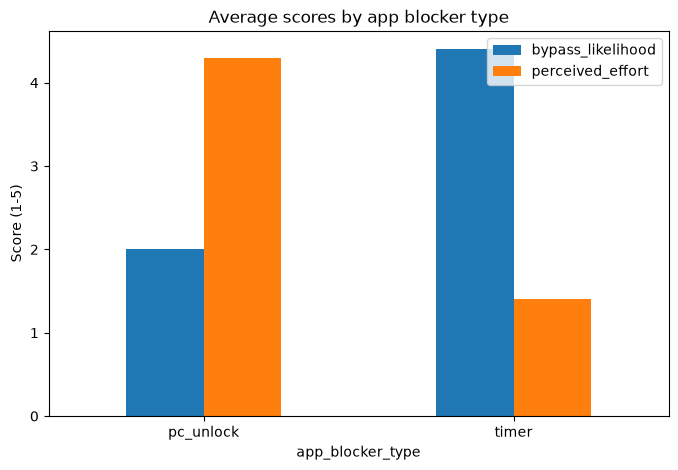

In [8]:
summary.plot(kind='bar', figsize=(8, 5))

plt.title('Average scores by app blocker type')
plt.ylabel('Score (1-5)')
plt.xticks(rotation=0)
plt.show()